# PET CIDADÃO
# GS 2026/2° Semestre — IA e ML


# Introdução

O Pet Cidadão é uma solução em app voltada à proteção e ao bem-estar animal na cidade de São Paulo. O aplicativo permite cadastrar animais desaparecidos ou encontrados,
registrar denúncias de abandono e maus-tratos e consultar serviços de apoio, como ONGs, abrigos, veterinários e campanhas de vacinação e castração.

Como complemento à proposta, este trabalho busca aplicar técnicas de Machine Learning à análise de solicitações públicas relacionadas a animais,
utilizando dados reais disponibilizados pela Prefeitura de São Paulo.

# Envolvimento de IA e ML

Gostaríamos de saber se seria possível prever, com base nas informações registradas quando uma solicitação relacionada a animais é aberta no SP156, se ela vai levar mais de 30 dias para ser encerrada. A gente escolheu esse período de 30 dias como referência para nossa análise.

A proposta consiste em investigar padrões nos registros do SP156 para entender melhor quais tipos de solicitações costumam demorar mais e como essas informações poderiam ser úteis para o nosso app.

Basicamente, olhando os pedidos antigos da Prefeitura, a gente quer ensinar a IA a reconhecer quais novas solicitações têm mais chance de demorar mais de 30 dias para serem finalizadas. Com isso, queremos identificar possíveis demoras e mostrar como essas previsões poderiam futuramente ajudar o app a orientar melhor os usuários.

# Rodar o notebook

Caso queira executar todo o notebook, é necessário antes entrar no link da nossa fonte, baixar o csv "arquivo-final-1-trim-26.csv" e carregar no ambiente

# Nossa fonte

Fonte: https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156 (Essa fonte vai de janeiro até março de 2026)

Baixar o csv: https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156/resource/75105148-4efd-48f3-8ae0-fc6c2adf7060


In [4]:
import pandas as pd

caminho = "/content/arquivo-final-1-trim-26.csv"

df = pd.read_csv(caminho, sep=";", encoding="latin1")

df.head()

/tmp/ipykernel_1145/952418591.py:5: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(caminho, sep=";", encoding="latin1")


,Data de Abertura,Data de Finalização,Meio de Comunicação,Tema,Assunto,Serviço,Status,Órgão,Logradouro,Número,CEP,Latitude,Longitude,Prefeitura Operacional,Distrito
0,01/01/2026,01/01/2026,CRM,Cidadania e assistência social,População ou pessoa em situação de rua,Baixas Temperaturas - Solicitar abordagem soci...,Finalizada,SMADS-SEAS República regional,Avenida Paulista,542.0,01310000,-23.567735,-46.648377,SE,BELA VISTA
1,01/01/2026,06/01/2026,PORTAL,Animais,Castração,Castrar Cães e Gatos Gratuitamente,Finalizada,SMS-DVZ-COSAP-Mboi Mirim,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01/01/2026,21/01/2026,CRM,Rua e bairro,Drenagem de água de chuva,"Solicitar limpeza de bueiros, boca de lobo e p...",Finalizada,INTEGRAÇÃO-AMLURB-FLIP,Rua Guilherme Espíndola Pequito,30.0,04937050,-23.688677,-46.764251,M BOI MIRIM,JARDIM ANGELA
3,01/01/2026,06/01/2026,PORTAL,Animais,Castração,Castrar Cães e Gatos Gratuitamente,Finalizada,SMS-DVZ-COSAP-Mboi Mirim,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01/01/2026,25/02/2026,PORTAL,Rua e bairro,Terrenos e imóveis,Denunciar falta de limpeza de terrenos e imóve...,Finalizada,INTEGRACAO-SGF,Rua Nazaré Rezek Farah,291.0,04367050,-23.652082,-46.667881,JABAQUARA,JABAQUARA


In [5]:
print("Dimensões do dataset:", df.shape)
print("\nTemas mais frequentes:")
print(df["Tema"].value_counts().head(15))
print("\nAssuntos relacionados a animais:")
print(df[df["Tema"] == "Animais"]["Assunto"].value_counts())

Dimensões do dataset: (577989, 15)

Temas mais frequentes:
Tema
Rua e bairro                      103443
Trânsito e Transporte              88077
Lixo e limpeza                     73852
Cidadania e assistência social     62774
Cultura, esporte e lazer           51759
Finanças                           38236
Animais                            35457
Meio Ambiente                      29356
Ouvidoria SUS                      19292
Urgência                           18202
Ouvidoria Geral do Município       17917
Saúde                              13784
Bilhete Único                       9065
Obras e imóveis                     3912
Documentos e licenças               3529
Name: count, dtype: int64

Assuntos relacionados a animais:
Assunto
Castração                                           15599
Animais que transmitem doenças ou risco à saúde      8753
Dengue/chikungunya/zika (mosquito aedes aegypti)     2931
Registro de animais - RGA                            2840
Animal em via pública

In [6]:
df_animais = df[df["Tema"] == "Animais"].copy()

print("Total de solicitações de animais:", df_animais.shape[0])

print("\nStatus das solicitações:")
print(df_animais["Status"].value_counts())

print("\nDatas de finalização ausentes:")
print(df_animais["Data de Finalização"].isna().sum())

print("\nExemplo das solicitações:")
display(df_animais[["Data de Abertura", "Data de Finalização", "Status"]].head(10))

Total de solicitações de animais: 35457

Status das solicitações:
Status
Finalizada      34293
Em Andamento      636
Aberto            282
Cancelada         246
Name: count, dtype: int64

Datas de finalização ausentes:
918

Exemplo das solicitações:


,Data de Abertura,Data de Finalização,Status
1,01/01/2026,06/01/2026,Finalizada
3,01/01/2026,06/01/2026,Finalizada
30,01/01/2026,14/01/2026,Finalizada
88,01/01/2026,20/02/2026,Finalizada
142,01/01/2026,23/01/2026,Finalizada
157,01/01/2026,15/01/2026,Finalizada
179,01/01/2026,08/01/2026,Finalizada
190,01/01/2026,08/01/2026,Finalizada
213,01/01/2026,07/01/2026,Finalizada
216,01/01/2026,07/01/2026,Finalizada


In [7]:
df_finalizadas = df_animais[df_animais["Status"] == "Finalizada"].copy()

df_finalizadas["Data de Abertura"] = pd.to_datetime(
    df_finalizadas["Data de Abertura"], dayfirst=True, errors="coerce"
)

df_finalizadas["Data de Finalização"] = pd.to_datetime(
    df_finalizadas["Data de Finalização"], dayfirst=True, errors="coerce"
)

df_finalizadas["Tempo de Finalização"] = (
    df_finalizadas["Data de Finalização"] - df_finalizadas["Data de Abertura"]
).dt.days

print("Total de solicitações finalizadas:", len(df_finalizadas))

print("\nEstatísticas do tempo de finalização:")
print(df_finalizadas["Tempo de Finalização"].describe())

print("\nDatas inválidas:", df_finalizadas["Tempo de Finalização"].isna().sum())
print("Tempos negativos:", (df_finalizadas["Tempo de Finalização"] < 0).sum())

df_finalizadas[["Data de Abertura", "Data de Finalização", "Tempo de Finalização"]].head(10)

Total de solicitações finalizadas: 34293

Estatísticas do tempo de finalização:
count    34293.000000
mean        15.860146
std         26.854235
min          0.000000
25%          1.000000
50%          6.000000
75%         17.000000
max        211.000000
Name: Tempo de Finalização, dtype: float64

Datas inválidas: 0
Tempos negativos: 0


,Data de Abertura,Data de Finalização,Tempo de Finalização
1,2026-01-01,2026-01-06,5
3,2026-01-01,2026-01-06,5
30,2026-01-01,2026-01-14,13
88,2026-01-01,2026-02-20,50
142,2026-01-01,2026-01-23,22
157,2026-01-01,2026-01-15,14
179,2026-01-01,2026-01-08,7
190,2026-01-01,2026-01-08,7
213,2026-01-01,2026-01-07,6
216,2026-01-01,2026-01-07,6


In [8]:
df_finalizadas["Mais de 30 dias"] = (
    df_finalizadas["Tempo de Finalização"] > 30
).astype(int)

print("Quantidade de solicitações por categoria:")
print(df_finalizadas["Mais de 30 dias"].value_counts())
print("\nPorcentagem de cada categoria:")
print((df_finalizadas["Mais de 30 dias"].value_counts(normalize=True) * 100).round(2))

Quantidade de solicitações por categoria:
Mais de 30 dias
0    29465
1     4828
Name: count, dtype: int64

Porcentagem de cada categoria:
Mais de 30 dias
0    85.92
1    14.08
Name: proportion, dtype: float64


Na celula de cima, das 34.293 solicitações de animais que foram finalizadas, 4.828 levaram mais de 30 dias pra serem encerradas. A ideia agora é usar esses dados pra treinar um modelo que vai estar tentando identificar quais solicitações têm mais chance de demorar tanto assim.

In [9]:
print("Colunas disponíveis:")
print(df_finalizadas.columns)
print("\nValores ausentes por coluna:")
print(df_finalizadas.isnull().sum())

Colunas disponíveis:
Index(['Data de Abertura', 'Data de Finalização', 'Meio de Comunicação',
       'Tema', 'Assunto', 'Serviço', 'Status', 'Órgão', 'Logradouro', 'Número',
       'CEP', 'Latitude', 'Longitude', 'Prefeitura Operacional', 'Distrito',
       'Tempo de Finalização', 'Mais de 30 dias'],
      dtype='object')

Valores ausentes por coluna:
Data de Abertura              0
Data de Finalização           0
Meio de Comunicação           0
Tema                          0
Assunto                       0
Serviço                       0
Status                        0
Órgão                         0
Logradouro                18426
Número                    18427
CEP                       18427
Latitude                  18426
Longitude                 18426
Prefeitura Operacional    18459
Distrito                  18441
Tempo de Finalização          0
Mais de 30 dias               0
dtype: int64


In [10]:
df_modelo = df_finalizadas[
    ["Meio de Comunicação", "Assunto", "Serviço",
     "Data de Abertura", "Mais de 30 dias"]
].copy()

df_modelo["Mês de Abertura"] = df_modelo["Data de Abertura"].dt.month
df_modelo["Dia da Semana"] = df_modelo["Data de Abertura"].dt.dayofweek
df_modelo = df_modelo.drop(columns=["Data de Abertura"])
df_modelo.head()

,Meio de Comunicação,Assunto,Serviço,Mais de 30 dias,Mês de Abertura,Dia da Semana
1,PORTAL,Castração,Castrar Cães e Gatos Gratuitamente,0,1,3
3,PORTAL,Castração,Castrar Cães e Gatos Gratuitamente,0,1,3
30,CRM,Animais que transmitem doenças ou risco à saúde,Abelhas e Vespas - Solicitar vistoria em ninhos,0,1,3
88,PORTAL,Castração,Castrar Cães e Gatos Gratuitamente,1,1,3
142,CRM,Criação inadequada de animais,Denunciar condições inadequadas de criação de ...,0,1,3


In [11]:
from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns=["Mais de 30 dias"])
y = df_modelo["Mais de 30 dias"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dados de treino:", X_treino.shape)
print("Dados de teste:", X_teste.shape)
print("\nRespostas no treino:")
print(y_treino.value_counts())
print("\nRespostas no teste:")
print(y_teste.value_counts())

Dados de treino: (27434, 5)
Dados de teste: (6859, 5)

Respostas no treino:
Mais de 30 dias
0    23572
1     3862
Name: count, dtype: int64

Respostas no teste:
Mais de 30 dias
0    5893
1     966
Name: count, dtype: int64


In [12]:
from sklearn.preprocessing import LabelEncoder

X_treino_cod = X_treino.copy()
X_teste_cod = X_teste.copy()

colunas_texto = ["Meio de Comunicação", "Assunto", "Serviço"]

for coluna in colunas_texto:
    encoder = LabelEncoder()

    X_treino_cod[coluna] = encoder.fit_transform(X_treino[coluna])

    categorias = dict(zip(encoder.classes_, range(len(encoder.classes_))))

    X_teste_cod[coluna] = (
        X_teste[coluna].map(categorias).fillna(-1).astype(int)
    )

X_treino_cod.head()

,Meio de Comunicação,Assunto,Serviço,Mês de Abertura,Dia da Semana
412932,1,4,23,3,2
483387,2,5,10,3,0
413919,2,5,10,3,6
503635,2,5,10,3,5
65191,1,1,0,1,6


In [13]:
from xgboost import XGBClassifier

modelo = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42
)

modelo.fit(X_treino_cod, y_treino)
print("Modelo treinado.")

Modelo treinado.


In [14]:
from sklearn.model_selection import GridSearchCV

parametros = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4],
    "learning_rate": [0.05, 0.1]
}

busca = GridSearchCV(
    XGBClassifier(random_state=42),
    parametros,
    cv=3,
    scoring="f1",
    n_jobs=-1
)

busca.fit(X_treino_cod, y_treino)
print("Melhores parâmetros:", busca.best_params_)
print("Melhor F1 na validação cruzada:", round(busca.best_score_, 4))

Melhores parâmetros: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
Melhor F1 na validação cruzada: 0.2183


In [15]:
resultados = pd.DataFrame(busca.cv_results_)

colunas = [
    "param_n_estimators",
    "param_max_depth",
    "param_learning_rate",
    "mean_test_score",
    "rank_test_score"
]

comparacao = resultados[colunas].copy()
comparacao = comparacao.sort_values("rank_test_score")
comparacao = comparacao.rename(columns={
    "param_n_estimators": "Árvores",
    "param_max_depth": "Profundidade",
    "param_learning_rate": "Taxa de aprendizado",
    "mean_test_score": "F1 médio",
    "rank_test_score": "Posição"
})

display(comparacao.round(4))

,Árvores,Profundidade,Taxa de aprendizado,F1 médio,Posição
11,300,4,0.10,0.2183,1
10,200,4,0.10,0.2031,2
5,300,4,0.05,0.1877,3
8,300,3,0.10,0.1841,4
7,200,3,0.10,0.1688,5
2,300,3,0.05,0.1648,6
4,200,4,0.05,0.1593,7
9,100,4,0.10,0.1562,8
1,200,3,0.05,0.1340,9
6,100,3,0.10,0.1319,10


In [16]:
from sklearn.metrics import classification_report, confusion_matrix

melhor_modelo = busca.best_estimator_

previsoes_treino = melhor_modelo.predict(X_treino_cod)
previsoes_teste = melhor_modelo.predict(X_teste_cod)

print("Resultados do treino:")
print(classification_report(y_treino, previsoes_treino, zero_division=0))
print("\nResultados do teste:")
print(classification_report(y_teste, previsoes_teste, zero_division=0))
print("\nMatriz de confusão do teste:")
print(confusion_matrix(y_teste, previsoes_teste))

Resultados do treino:
              precision    recall  f1-score   support

           0       0.87      0.99      0.93     23572
           1       0.66      0.12      0.20      3862

    accuracy                           0.87     27434
   macro avg       0.77      0.55      0.56     27434
weighted avg       0.84      0.87      0.83     27434


Resultados do teste:
              precision    recall  f1-score   support

           0       0.87      0.99      0.93      5893
           1       0.60      0.10      0.16       966

    accuracy                           0.86      6859
   macro avg       0.74      0.54      0.55      6859
weighted avg       0.83      0.86      0.82      6859


Matriz de confusão do teste:
[[5832   61]
 [ 874   92]]


### Esses são nossos primeiros resultados até agora

Depois de testar 12 combinações de hiperparâmetros, a melhor configuração do XGBoost nos mostrou um F1 médio de 0,2183 na validação cruzada.

Na avaliação final, o modelo alcançou uns 86% de acurácia no conjunto de teste. Apesar disso, teve dificuldade para identificar as solicitações que levaram mais de 30 dias para serem finalizadas.

Das 966 solicitações que ultrapassaram esse período no conjunto de teste, o modelo conseguiu identificar corretamente apenas 92.

Com isso dá pra entender que mesmo tendo uma acurácia até que alta, ainda precisamos buscar um jeito de melhorar a identificação das solicitações mais demoradas.

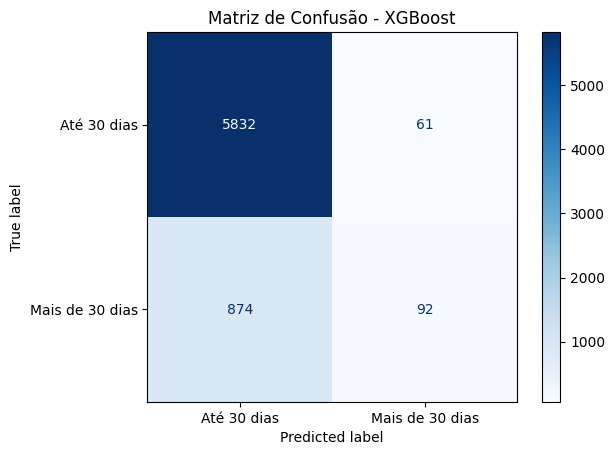

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes_teste,
    display_labels=["Até 30 dias", "Mais de 30 dias"],
    values_format="d",
    cmap="Blues"
)

plt.title("Matriz de Confusão - XGBoost")
plt.show()

In [18]:
from sklearn.model_selection import cross_val_score

peso = (y_treino == 0).sum() / (y_treino == 1).sum()

modelo_balanceado = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=peso,
    random_state=42
)

f1_balanceado = cross_val_score(
    modelo_balanceado,
    X_treino_cod,
    y_treino,
    cv=3,
    scoring="f1"
)

print("Peso da classe 1:", round(peso, 2))
print("F1 do modelo original:", round(busca.best_score_, 4))
print("F1 do modelo balanceado:", round(f1_balanceado.mean(), 4))

Peso da classe 1: 6.1
F1 do modelo original: 0.2183
F1 do modelo balanceado: 0.5631


In [19]:
modelo_balanceado.fit(X_treino_cod, y_treino)

previsoes_balanceadas_treino = modelo_balanceado.predict(X_treino_cod)
previsoes_balanceadas_teste = modelo_balanceado.predict(X_teste_cod)

print("Modelo balanceado - Treino:")
print(classification_report(
    y_treino, previsoes_balanceadas_treino, zero_division=0
))

print("\nModelo balanceado - Teste:")
print(classification_report(
    y_teste, previsoes_balanceadas_teste, zero_division=0
))

print("\nMatriz de confusão do modelo balanceado:")
print(confusion_matrix(y_teste, previsoes_balanceadas_teste))

Modelo balanceado - Treino:
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     23572
           1       0.42      0.88      0.57      3862

    accuracy                           0.81     27434
   macro avg       0.70      0.84      0.72     27434
weighted avg       0.90      0.81      0.83     27434


Modelo balanceado - Teste:
              precision    recall  f1-score   support

           0       0.98      0.80      0.88      5893
           1       0.41      0.88      0.56       966

    accuracy                           0.81      6859
   macro avg       0.69      0.84      0.72      6859
weighted avg       0.90      0.81      0.83      6859


Matriz de confusão do modelo balanceado:
[[4699 1194]
 [ 120  846]]


# Testando uma melhoria no modelo

Como a maioria das solicitações foi finalizada em até 30 dias, resolvemos testar uma mudança no XGBoost para ele prestar mais atenção nas que demoraram mais.

O resultado foi bem melhor. Antes, o modelo tinha um F1 de 0,2183 na validação cruzada, mas depois da mudança chegou a 0,5631.

Nos testes, o primeiro modelo conseguiu identificar só 92 das 966 solicitações que demoraram mais de 30 dias. Já o novo conseguiu identificar 846.

Só que também teve um problema que é ele ter começado a errar mais nas solicitações que não demoraram tanto, passando de 61 para 1.194 erros desse tipo. A porcentagem geral de acertos também caiu de 86% para 81%.

Mesmo assim, achamos que essa mudança até que ajudou bastante, já que nossa ideia é realmente tentar identificar quais solicitações podem estar demorando mais. Ainda vamos precisar considerar esses erros.

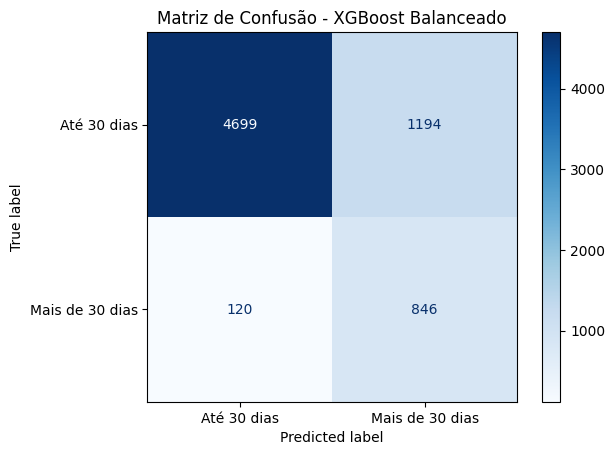

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes_balanceadas_teste,
    display_labels=["Até 30 dias", "Mais de 30 dias"],
    values_format="d",
    cmap="Blues"
)

plt.title("Matriz de Confusão - XGBoost Balanceado")
plt.show()

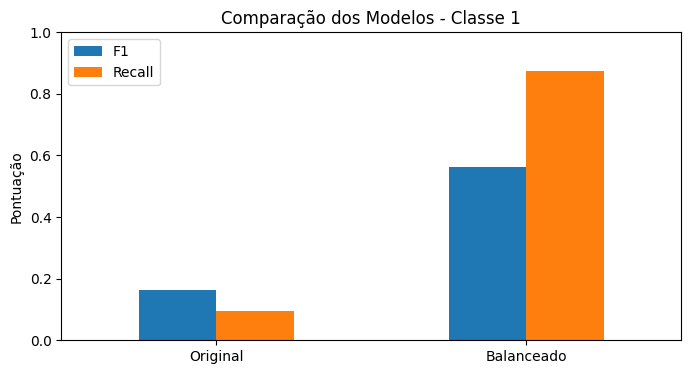

In [21]:
from sklearn.metrics import f1_score, recall_score

comparacao_modelos = pd.DataFrame({
    "F1": [
        f1_score(y_teste, previsoes_teste),
        f1_score(y_teste, previsoes_balanceadas_teste)
    ],
    "Recall": [
        recall_score(y_teste, previsoes_teste),
        recall_score(y_teste, previsoes_balanceadas_teste)
    ]
}, index=["Original", "Balanceado"])

comparacao_modelos.plot(kind="bar", figsize=(8, 4))

plt.title("Comparação dos Modelos - Classe 1")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

,Treino,Teste
Original,0.1998,0.1644
Balanceado,0.5665,0.5629


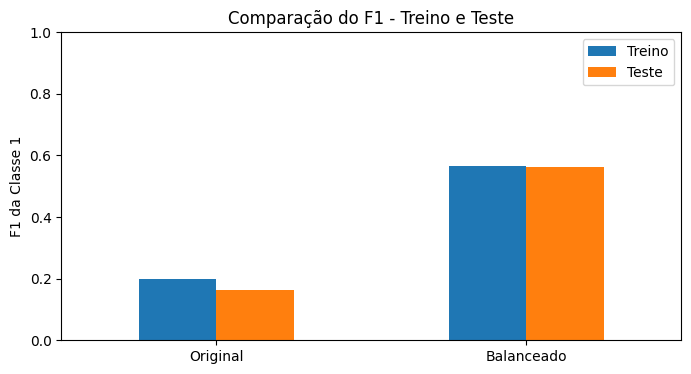

In [22]:
from sklearn.metrics import f1_score

comparacao_treino_teste = pd.DataFrame({
    "Treino": [
        f1_score(y_treino, previsoes_treino),
        f1_score(y_treino, previsoes_balanceadas_treino)
    ],
    "Teste": [
        f1_score(y_teste, previsoes_teste),
        f1_score(y_teste, previsoes_balanceadas_teste)
    ]
}, index=["Original", "Balanceado"])

display(comparacao_treino_teste.round(4))
comparacao_treino_teste.plot(kind="bar", figsize=(8, 4))
plt.title("Comparação do F1 - Treino e Teste")
plt.ylabel("F1 da Classe 1")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# Conclusão

Bom, depois dos testes que fizemos, conseguimos melhorar bastante nosso modelo. No começo ele identificava só 92 das 966 solicitações que demoraram mais de 30 dias, mas depois do balanceamento conseguimos chegar a 846.

Só que isso também trouxe alguns problemas. O modelo começou a apontar várias solicitações como demoradas mesmo quando elas eram finalizadas antes dos 30 dias. Foram 1.194 erros desse tipo.

Uma coisa boa é que os resultados do treino e do teste ficaram parecidos. O F1 do modelo balanceado foi de 0,57 no treino e 0,56 no teste, então aparentemente não tivemos um problema muito grande de overfitting.

Também temos que lembrar que usamos apenas solicitações já finalizadas e que uma solicitação encerrada no SP156 não significa necessariamente que o problema do animal foi resolvido.

Outra coisa é que o tema "Animais" do SP156 não tem só solicitações sobre cães e gatos. Também encontramos assuntos como dengue e animais que transmitem doenças, então nosso modelo acabou analisando outros tipos de solicitações além das que têm relação direta com o Pet Cidadão.

No geral, achamos que o resultado foi bem interessante. Conseguimos melhorar bastante o modelo e mostrar que dá pra encontrar alguns padrões nos pedidos da Prefeitura. Mesmo com os erros que tivemos, a gente conseguiu explorar uma forma de usar essas informações para ajudar na proposta do Pet Cidadão.